
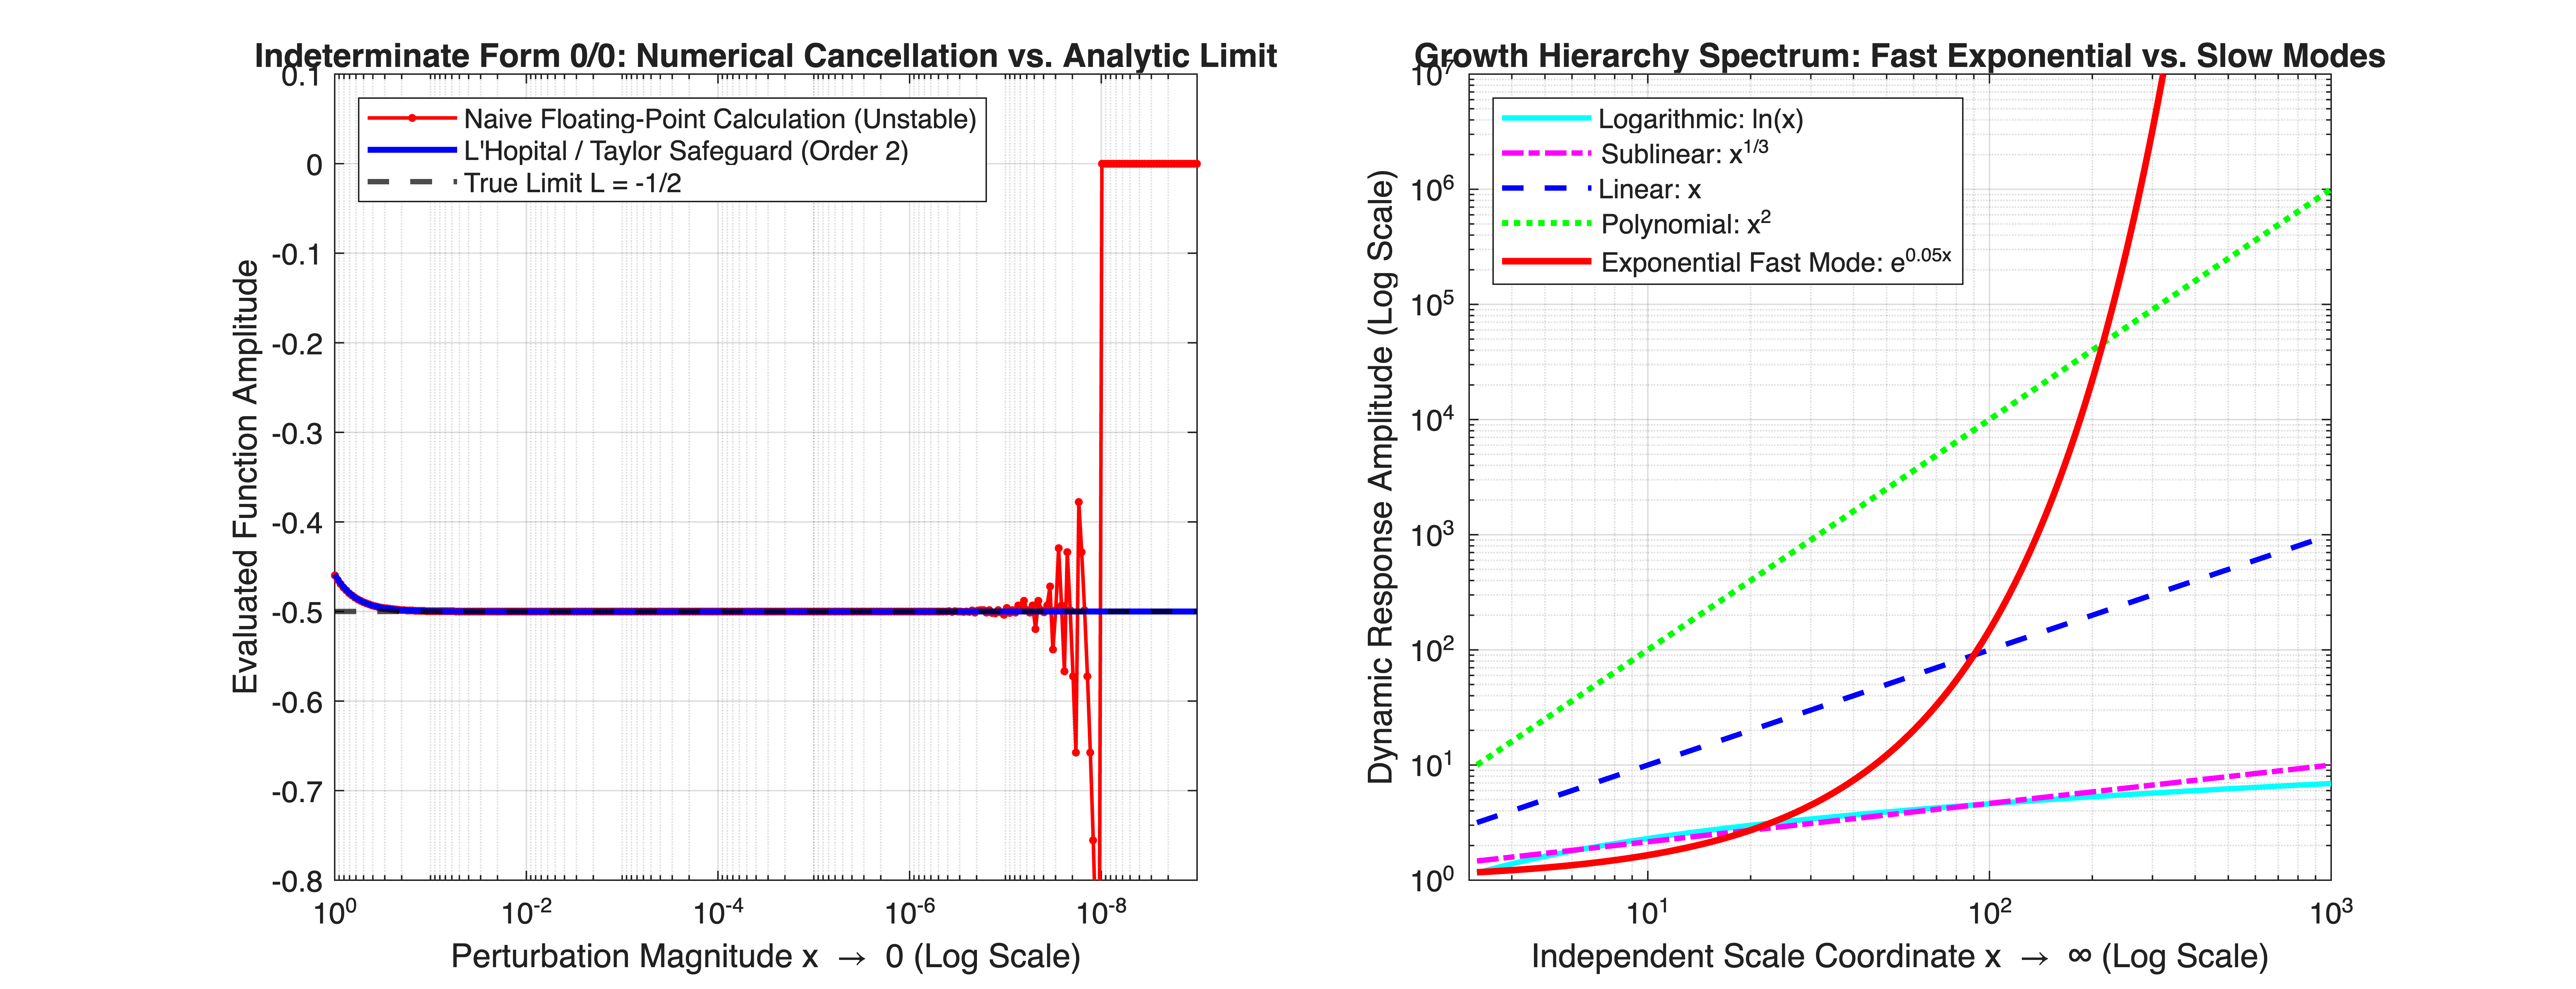

In [1]:
%% MIT 18.01 Lecture 34: Indeterminate Limits, Numerical Stability & Growth Spectra
% Mathematical Tool Application: Used for designing division-by-zero protection guards
% in embedded quaternion/sinc control, evaluating DC gains of indeterminate plant transfer
% functions, and analyzing fast-slow scale separation in stiff dynamic systems.


clear; clc; close all;


%% Part 1: Indeterminate Form Numerical Stability: f(x) = (cos(x) - 1) / x^2
% Analytical Limit via Lecture 34 L'Hopital / Taylor: -1/2 = -0.5
exact_limit = -0.5;


% Generate perturbation values approaching zero on log scale: x from 1 down to 10^(-10)
x_log_span = logspace(0, -9, 300);


% 1. Naive Direct Floating-Point Evaluation (Suffers from cancellation error near 0)
f_naive = (cos(x_log_span) - 1.0) ./ (x_log_span.^2);


% 2. 2nd-Order Taylor Approximation Safeguard: cos(x) approx 1 - x^2/2 + x^4/24
% (cos(x) - 1)/x^2 approx -1/2 + x^2/24
f_taylor_safeguard = -0.5 + (x_log_span.^2) / 24.0;


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
semilogx(x_log_span, f_naive, 'r.-', 'LineWidth', 1.2, 'MarkerSize', 8, ...
    'DisplayName', 'Naive Floating-Point Calculation (Unstable)'); hold on;
semilogx(x_log_span, f_taylor_safeguard, 'b-', 'LineWidth', 2.0, ...
    'DisplayName', 'L''Hopital / Taylor Safeguard (Order 2)');
yline(exact_limit, 'k--', 'LineWidth', 1.8, 'DisplayName', 'True Limit L = -1/2');


set(gca, 'XDir', 'reverse'); % Heading towards 0 to the right
grid on;
xlim([1e-9, 1.0]); ylim([-0.8, 0.1]);
xlabel('Perturbation Magnitude x \rightarrow 0 (Log Scale)');
ylabel('Evaluated Function Amplitude');
title('Indeterminate Form 0/0: Numerical Cancellation vs. Analytic Limit');
legend('Location', 'northwest');


%% Part 2: Dynamic Growth Rate Hierarchy Spectrum at Infinity (Examples 7-9)
% Curves: ln(x) << x^(1/3) << x << x^2 << exp(0.2*x)
subplot(1, 2, 2);


x_domain_inf = logspace(0.5, 3.0, 300); % x from ~3 to 1000


y_log  = log(x_domain_inf);
y_cbrt = x_domain_inf.^(1.0 / 3.0);
y_lin  = x_domain_inf;
y_quad = x_domain_inf.^2;
y_exp  = exp(0.05 * x_domain_inf); % Scaled exponential


loglog(x_domain_inf, y_log,  'c-',  'LineWidth', 1.8, 'DisplayName', 'Logarithmic: ln(x)'); hold on;
loglog(x_domain_inf, y_cbrt, 'm-.', 'LineWidth', 1.8, 'DisplayName', 'Sublinear: x^{1/3}');
loglog(x_domain_inf, y_lin,  'b--', 'LineWidth', 1.8, 'DisplayName', 'Linear: x');
loglog(x_domain_inf, y_quad, 'g:',  'LineWidth', 2.0, 'DisplayName', 'Polynomial: x^2');
loglog(x_domain_inf, y_exp,  'r-',  'LineWidth', 2.2, 'DisplayName', 'Exponential Fast Mode: e^{0.05x}');


grid on;
xlim([3, 1000]); ylim([1, 1e7]);
xlabel('Independent Scale Coordinate x \rightarrow \infty (Log Scale)');
ylabel('Dynamic Response Amplitude (Log Scale)');
title('Growth Hierarchy Spectrum: Fast Exponential vs. Slow Modes');
legend('Location', 'northwest');

In [2]:


%% Console Proof of Power Indeterminate Form 0^0: lim x^x = 1 (Example 10)
x_test_small = [0.1, 0.01, 1e-4, 1e-6, 1e-9];
fprintf('=== Lecture 34 Power Indeterminate Proof: lim_{x \\rightarrow 0^+} x^x ===\n');

ightarrow 0^+} x^x ===

In [3]:
for i = 1:length(x_test_small)
    xi = x_test_small(i);
    fprintf('  x = %1.0e: x*ln(x) = %11.4e => x^x = exp(x*ln(x)) = %14.10f\n', ...
        xi, xi * log(xi), xi^xi);
end

  x = 1e-01: x*ln(x) = -2.3026e-01 => x^x = exp(x*ln(x)) =   0.7943282347
  x = 1e-02: x*ln(x) = -4.6052e-02 => x^x = exp(x*ln(x)) =   0.9549925860
  x = 1e-04: x*ln(x) = -9.2103e-04 => x^x = exp(x*ln(x)) =   0.9990793900
  x = 1e-06: x*ln(x) = -1.3816e-05 => x^x = exp(x*ln(x)) =   0.9999861846
  x = 1e-09: x*ln(x) = -2.0723e-08 => x^x = exp(x*ln(x)) =   0.9999999793

In [4]:
fprintf('Analytic Confirmation: lim x*ln(x) = 0 via L''Hopital => lim x^x = e^0 = 1.0000000000\n');

Analytic Confirmation: lim x*ln(x) = 0 via L'Hopital => lim x^x = e^0 = 1.0000000000